# **NLP16: Optimalizácia pristávania kozmickej lode**



## Úloha C – Implementácia optimalizačných úloh

Cieľom je implementovať optimalizačné úlohy z častí A a B.
Na začiatok importujeme potrebné knižnice:

- `numpy` – na matematické výpočty a prácu s vektormi a maticami,
- `matplotlib` – na grafické znázornenie výsledkov,
- `cvxpy` – na formuláciu a riešenie konvexných optimalizačných úloh (napr. SOCP).


In [40]:
import numpy as np
import matplotlib.pyplot as plt
import cvxpy as cp


Ďalej definujeme parametre, ktoré sme prevzali z priloženého
súboru `spacecraft_landing_data.py`:

- `h` – dĺžka jednej časovej periódy,
- `g` – gravitačné zrýchlenie,
- `m` – hmotnosť kozmickej lode,
- `Fmax` – maximálna povolená veľkosť ťahovej sily,
- `p0` – počiatočná poloha lode,
- `v0` – počiatočná rýchlosť lode,
- `alpha` – parameter určujúci kužeľovú oblasť,
- `gamma` – koeficient spotreby paliva,
- `K` – počet časových periód.


In [41]:
h = 1.0
g = 0.1
m = 10.0
Fmax = 10.0
p0 = np.array([50.0, 50.0, 100.0])
v0 = np.array([-10.0, 0.0, -10.0])
alpha = 0.5
gamma = 1.0
K = 35

**Formulácia optimalizačného modelu**

Teraz vytvoríme funkciu `spotreba_paliva(K, minimalizacia=True)`,
ktorá zostaví optimalizačnú úlohu z časti A.

Najprv definujeme rozhodovacie premenné:
- `p` – polohy lode,
- `v` – rýchlosti lode,
- `f` – ťahové sily motora.

Následne pridáme všetky obmedzenia zo zadania:
počiatočné a koncové podmienky, dynamické rovnice,
obmedzenie maximálneho ťahu a kužeľové obmedzenie.

Podľa hodnoty parametra `minimalizacia` zvolíme
účelovú funkciu:

- `True` – minimalizujeme celkovú spotrebu paliva
  pomocou funkcie $\gamma h\sum_{k=1}^K\|f_k\|_2$.
- `False` – minimalizujeme konštantu 0, čím iba
  overujeme existenciu prípustného riešenia - ako v časti B.

Funkcia vracia zostavenú optimalizačnú úlohu
a rozhodovacie premenné `p`, `v` a `f`.
Samotnú optimalizáciu vykonáme až v solveri.


In [42]:
def spotreba_paliva(K, minimalizacia=True):
    p = cp.Variable((3, K + 1))
    v = cp.Variable((3, K + 1))
    f = cp.Variable((3, K))

    e3 = np.array([0.0, 0.0, 1.0])

    constraints = [
        p[:, 0] == p0,
        v[:, 0] == v0,
        p[:, K] == 0,
        v[:, K] == 0
    ]

    for k in range(K):
        # rovnica rýchlosti
        constraints.append(
            v[:, k + 1] ==
            v[:, k] + (h / m) * f[:, k] - h * g * e3
        )

        # rovnica polohy
        constraints.append(
            p[:, k + 1] ==
            p[:, k] + (h / 2) * (v[:, k] + v[:, k + 1])
        )

        # maximálny ťah
        constraints.append(
            cp.norm(f[:, k], 2) <= Fmax
        )

    # kužeľové obmedzenie
    for k in range(K + 1):
        constraints.append(
            alpha * cp.norm(p[:2, k], 2) <= p[2, k]
        )

    if minimalizacia:
        objective = cp.Minimize(
            gamma * h *
            cp.sum(cp.norm(f, 2, axis=0))
        )
    else:
        objective = cp.Minimize(0)

    problem = cp.Problem(objective, constraints)

    return problem, p, v, f



### Minimalizácia spotreby paliva

Pre pevne stanovený počet periód $K=35$ vyriešime
optimalizačnú úlohu. Cieľom je nájsť
optimálny ťahový profil, pri ktorom bude celková
spotreba paliva minimálna.

Pomocou funkcie `spotreba_paliva` zostavíme
optimalizačný model a vyriešime ho solverom CLARABEL.
Následne získame optimálne hodnoty polôh,
rýchlostí a ťahových síl.


In [43]:
uloha, poloha, rychlost, tah = spotreba_paliva(K=35, minimalizacia=True)

uloha.solve(solver=cp.CLARABEL)

print(uloha.status)

poloha_opt = poloha.value
rychlost_opt = rychlost.value
tah_opt = tah.value


optimal



Z optimálneho riešenia vypočítame celkovú spotrebu
paliva pomocou diskrétnej účelovej funkcie

$$
J^{*}=\gamma h\sum_{k=1}^{35}\|f_k^{*}\|_2.
$$

Zároveň vypíšeme optimálny ťahový profil, ktorý
pozostáva z troch zložiek ťahovej sily pre každú
z periód.



In [44]:
J_opt = gamma * h * np.sum(
    np.linalg.norm(tah_opt, axis=0)
)

print("Čas pristátia:", K * h)
print("Minimálna spotreba:", J_opt)
print("Optimálny ťahový profil:\n", np.round(tah_opt, 3))


Čas pristátia: 35.0
Minimálna spotreba: 192.99122400640536
Optimálny ťahový profil:
 [[ 6.483  6.519  6.558  6.6    6.648  6.701  6.76   6.827  6.902  6.987
   7.083  7.191  7.312  7.442  7.568  7.456  2.519  0.     0.     0.
   0.     0.     0.     0.     0.     0.     0.    -0.    -0.    -0.
  -0.    -0.    -3.885 -4.614 -5.056]
 [-2.424 -2.345 -2.256 -2.157 -2.044 -1.915 -1.766 -1.592 -1.388 -1.144
  -0.849 -0.485 -0.028  0.559  1.329  1.94   0.791  0.     0.     0.
   0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
   0.     0.     5.097  5.363  5.313]
 [ 7.217  7.212  7.205  7.196  7.185  7.172  7.154  7.132  7.102  7.062
   7.008  6.932  6.821  6.656  6.399  6.375  2.381  0.     0.     0.
   0.     0.     0.     0.     0.     0.     0.     0.     0.     0.
   0.     0.     6.925  7.067  6.798]]


### Minimalizácia času pristátia

Najprv vytvoríme pomocnú funkciu `over_pripustnost(K)`,
ktorá zostavenú úlohu vyrieši solverom CLARABEL.

Ak solver nájde optimálne riešenie, úlohu
považujeme za prípustnú. Ak solver zahlási
neprípustnosť, pre dané K neexistuje
pristátie spĺňajúce všetky obmedzenia.




In [45]:
def over_pripustnost(K):
    uloha, p, v, f = spotreba_paliva(
        K, minimalizacia=False
    )

    uloha.solve(solver=cp.CLARABEL)

    if uloha.status == "optimal":
        return True, p.value, v.value, f.value

    elif uloha.status == "infeasible":
        return False, None, None, None

    else:
        raise RuntimeError(
            f"K={K}: {uloha.status}"
        )


Cieľom je nájsť najmenší počet periód $K_{\min}$,
pre ktorý existuje prípustný pristávací manéver.


---



**Exponenciálne vyhľadávanie**


Najprv nájdeme prípustnú hornú hranicu $K_R$.

Začneme s $K_L=0$ a $K_R=1$. Ak je úloha pre
dané $K_R$ neprípustná, nastavíme $K_L=K_R$
a hornú hranicu zdvojnásobíme.

Postup opakujeme, až kým nenájdeme prípustné
riešenie alebo nedosiahneme maximálny skúmaný
počet periód $K_{\max}=100$.



In [46]:
K_max = 100
K_L = 0
K_R = 1

while True:
    pripustna, _, _, _ = over_pripustnost(K_R)

    print(f"K = {K_R}:",
          "prípustná" if pripustna else "neprípustná")

    if pripustna:
        break

    if K_R == K_max:
        raise RuntimeError(
            "Neexistuje prípustné riešenie, K_R == K_max."
        )

    K_L = K_R
    K_R = min(2 * K_R, K_max)

print("Dolná hranica:", K_L)
print("Horná hranica:", K_R)


K = 1: neprípustná
K = 2: neprípustná
K = 4: neprípustná
K = 8: neprípustná
K = 16: neprípustná
K = 32: prípustná
Dolná hranica: 16
Horná hranica: 32


**Binárne vyhľadávanie**

Máme neprípustnú dolnú hranicu $K_L = 16$ a prípustnú hornú hranicu $K_R = 32$.

V každej iterácii vypočítame stred intervalu

$$
K=\left\lfloor\frac{K_L+K_R}{2}\right\rfloor
$$

a overíme, či je pre túto hodnotu úloha prípustná.

Ak áno, znížime hornú hranicu na K.
Ak nie, zvýšime dolnú hranicu na K.

Postup opakujeme, až kým $K_R-K_L=1$.


In [47]:
while K_R - K_L > 1:
    K_stred = (K_L + K_R) // 2

    pripustna, _, _, _ = over_pripustnost(K_stred)

    print(f"K = {K_stred}:",
          "prípustná" if pripustna else "neprípustná")

    if pripustna:
        K_R = K_stred
    else:
        K_L = K_stred

K_min = K_R
T_min = K_min * h

print("Minimálny počet periód:", K_min)
print("Minimálny čas pristátia:", T_min)


K = 24: neprípustná
K = 28: prípustná
K = 26: prípustná
K = 25: prípustná
Minimálny počet periód: 25
Minimálny čas pristátia: 25.0


**Prípustný ťahový profil pri minimálnom čase**

Pre vypočítanú hodnotu $K_{\min}$ opäť vyriešime
úlohu prípustnosti a získame príslušný ťahový
profil.

Tento profil nemusí minimalizovať spotrebu paliva,
keďže v tejto časti sme optimalizovali iba čas
pristátia.


In [48]:
pripustna, poloha_min, rychlost_min, tah_min = (
    over_pripustnost(K_min)
)

print("Prípustný ťahový profil:\n", np.round(tah_min, 3))


Prípustný ťahový profil:
 [[ 6.537  6.562  6.592  6.627  6.667  6.714  6.771  6.839  6.924  7.031
   7.172  7.366  7.647  8.077  8.786  9.824  9.626  9.228  6.444 -3.256
  -6.841 -7.693 -7.949 -7.966 -7.727]
 [-2.739 -2.732 -2.722 -2.71  -2.696 -2.679 -2.659 -2.635 -2.604 -2.564
  -2.509 -2.432 -2.312 -2.101 -1.681 -0.642  1.295  3.198  7.47   8.454
   5.468  4.04   3.283  2.798  2.413]
 [ 7.051  7.03   7.005  6.977  6.944  6.904  6.856  6.796  6.721  6.624
   6.491  6.298  5.997  5.485  4.429  1.545 -2.234 -1.757  0.179  3.95
   4.679  4.854  5.036  5.307  5.832]]


### Minimalizácia spotreby paliva pri najkratšom čase pristátia

V predchádzajúcej časti sme získali najmenší
prípustný počet periód $K_{\min}=25$.

Teraz pre túto hodnotu opäť vyriešime úlohu
minimalizácie spotreby paliva. Použijeme funkciu `spotreba_paliva(K_min, minimalizacia=True)`.
Následne vypočítame minimálnu spotrebu $J_{\min}$.


In [49]:
uloha_min, poloha_min, rychlost_min, tah_min = spotreba_paliva(
    K_min, minimalizacia=True
)

uloha_min.solve(solver=cp.CLARABEL)

print(uloha_min.status)

poloha_min_opt = poloha_min.value
rychlost_min_opt = rychlost_min.value
tah_min_opt = tah_min.value

J_min = gamma * h * np.sum(
    np.linalg.norm(tah_min_opt, axis=0)
)

print("Minimálna spotreba paliva pri K_min:", J_min)


optimal
Minimálna spotreba paliva pri K_min: 245.63002102874972


## Úloha D -  Grafické znázornenie pristávacích manévrov


Z priloženého súboru `spacecraft_landing_data.py`  prevezmeme funkciu `plot_trajectory(p, f)`, ktorú využijeme pri vizualizácii výsledkov.

Funkcia vytvorí trojrozmerný graf, v ktorom znázorní
kužeľovú oblasť, trajektóriu pristávania a vektory
ťahových síl v jednotlivých periódach.

Ako argumenty prijíma:
- `p` – maticu polôh lode s rozmermi (3, K+1),
- `f` – maticu ťahových síl s rozmermi (3, K).

Funkcia najprv overí rozmery vstupných matíc
a následne vykreslí trajektóriu a ťahy motora.

In [50]:
def plot_trajectory(p, f, title="Spacecraft landing trajectory and thrust"):
    p = np.asarray(p, dtype=float)
    f = np.asarray(f, dtype=float)
    if p.shape != (3, K + 1):
        raise ValueError(f"Expected p.shape == (3, {K+1}), got {p.shape}")
    if f.shape != (3, K):
        raise ValueError(f"Expected f.shape == (3, {K}), got {f.shape}")

    x = np.linspace(-40, 55, 30)
    y = np.linspace(0, 55, 30)
    X, Y = np.meshgrid(x, y)
    Z = alpha * np.sqrt(X**2 + Y**2)

    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection="3d")
    ax.plot_surface(X, Y, Z, cmap="autumn", alpha=0.55,
                    linewidth=0, antialiased=True)
    ax.set_xlim(-40, 55)
    ax.set_ylim(0, 55)
    ax.set_zlim(0, 105)

    ax.plot(p[0, :], p[1, :], p[2, :], color="blue", linewidth=1.5,
            label="Trajectory")
    ax.quiver(p[0, :K], p[1, :K], p[2, :K],
              f[0, :], f[1, :], f[2, :],
              length=0.3, normalize=False, color="black", linewidth=1.0)

    ax.set_xlabel("p1")
    ax.set_ylabel("p2")
    ax.set_zlabel("p3")
    ax.set_title(title)
    ax.legend()
    plt.tight_layout()
    plt.show()
    return fig, ax

### Priestorová trajektória kozmickej lode

Pomocou funkcie `plot_trajectory` vykreslíme optimálne
trajektórie pre oba časy pristátia $K_p = 25$, $K_m = 35$.

Grafy zobrazujú polohu lode v trojrozmernom priestore a
hranicu prípustnej kužeľovej oblasti.


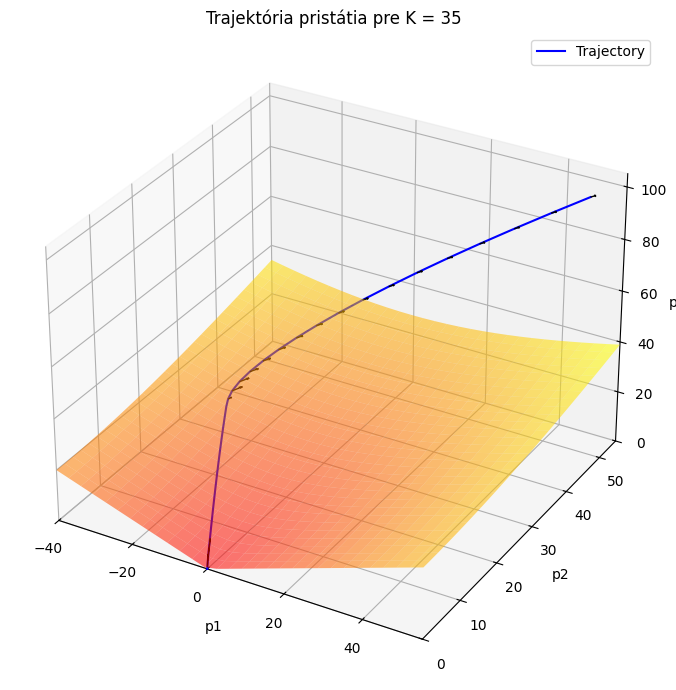

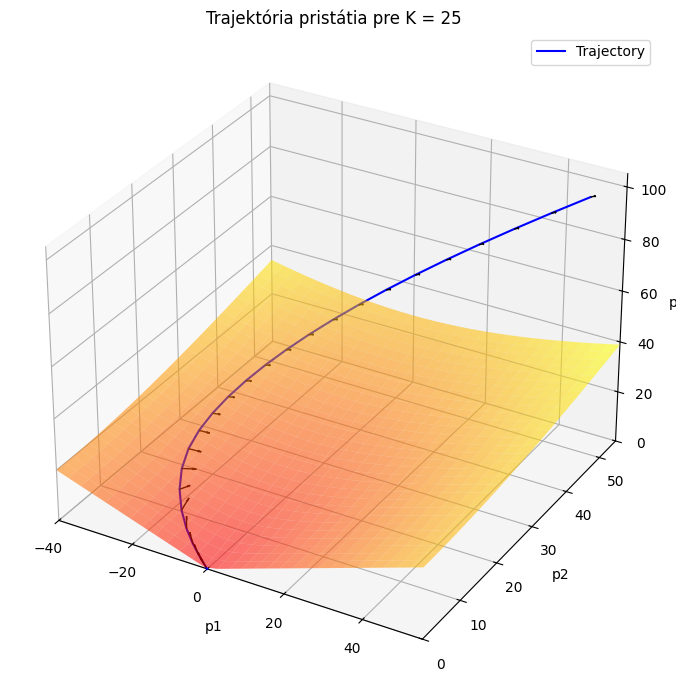

In [51]:
# trajektória pre K = 35
K = 35
fig_p, ax_p = plot_trajectory(poloha_opt, tah_opt, title="Trajektória pristátia pre K = 35")
fig_p.savefig("trajektoria_p.png", dpi=200, bbox_inches="tight")

# trajektória pre K = 25
K = 25
fig_m, ax_m = plot_trajectory(poloha_min_opt, tah_min_opt, title="Trajektória pristátia pre K = 25")
fig_p.savefig("trajektoria_m.png", dpi=200, bbox_inches="tight")


### Veľkosť ťahovej sily v závislosti od času

Pre oba pristávacie manévre vypočítame veľkosť
ťahovej sily $\|f_k\|_2$ v jednotlivých periódach
pomocou euklidovskej normy (`np.linalg.norm`).

Následne vykreslíme dva samostatné schodovité grafy pre $K_p=35$ a $K_m=25$, keďže ťahová sila je počas každej periódy konštantná. V oboch grafoch vyznačíme aj maximálnu povolenú ťahovú silu $F^{\max}=10$.

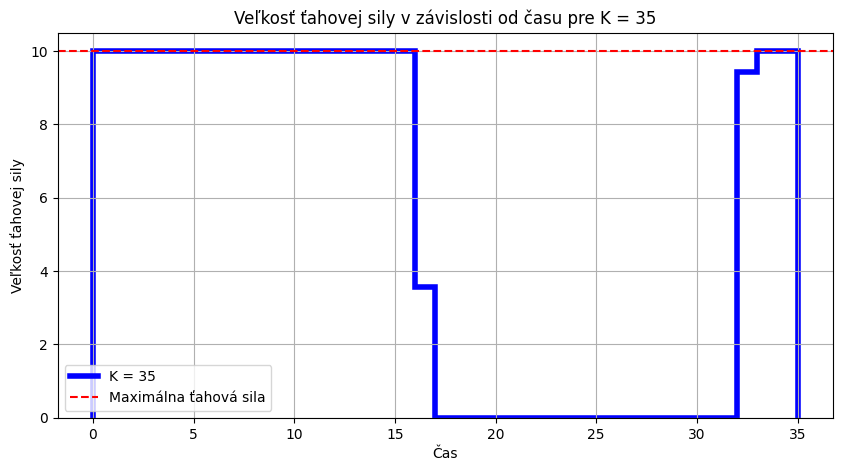

In [52]:
velkost_p = np.linalg.norm(tah_opt, axis=0)

cas_p = np.arange(len(velkost_p) + 1) * h

plt.figure(figsize=(10, 5))
plt.stairs(velkost_p, cas_p, label="K = 35", linewidth=4, color="blue")

plt.axhline(Fmax, color="red", linestyle="--", label="Maximálna ťahová sila")

plt.xlabel("Čas")
plt.ylabel("Veľkosť ťahovej sily")
plt.title("Veľkosť ťahovej sily v závislosti od času pre K = 35")
plt.legend()
plt.grid(True)

plt.savefig("velkost_tahu_p.png", dpi=200, bbox_inches="tight")
plt.show()


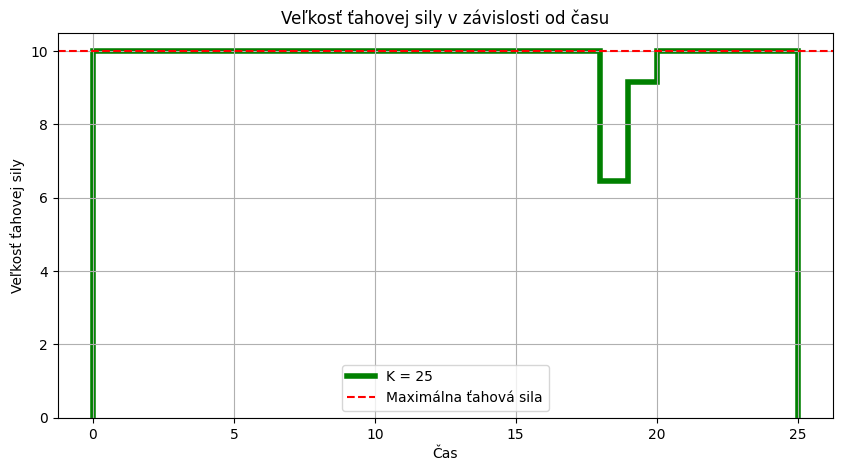

In [53]:
velkost_m = np.linalg.norm(tah_min_opt, axis=0)

cas_m = np.arange(len(velkost_m) + 1) * h

plt.figure(figsize=(10, 5))
plt.stairs(velkost_m, cas_m, label="K = 25", linewidth=4, color="green")

plt.axhline(Fmax, color="red", linestyle="--", label="Maximálna ťahová sila")

plt.xlabel("Čas")
plt.ylabel("Veľkosť ťahovej sily")
plt.title("Veľkosť ťahovej sily v závislosti od času")
plt.legend()
plt.grid(True)

plt.savefig("velkost_tahu_m.png", dpi=200, bbox_inches="tight")
plt.show()

### Jednotlivé zložky ťahovej sily

Vykreslíme jednotlivé zložky ťahovej sily
$f_{k,1}$, $f_{k,2}$ a $f_{k,3}$ v závislosti od času.

Pre každú zložku vytvoríme samostatný graf, v ktorom
budú spolu znázornené $K_p=35$ a $K_m=25$.Vyznačíme aj nulovú
hodnotu, aby bolo viditeľné, kde jednotlivé zložky menia znamienko.

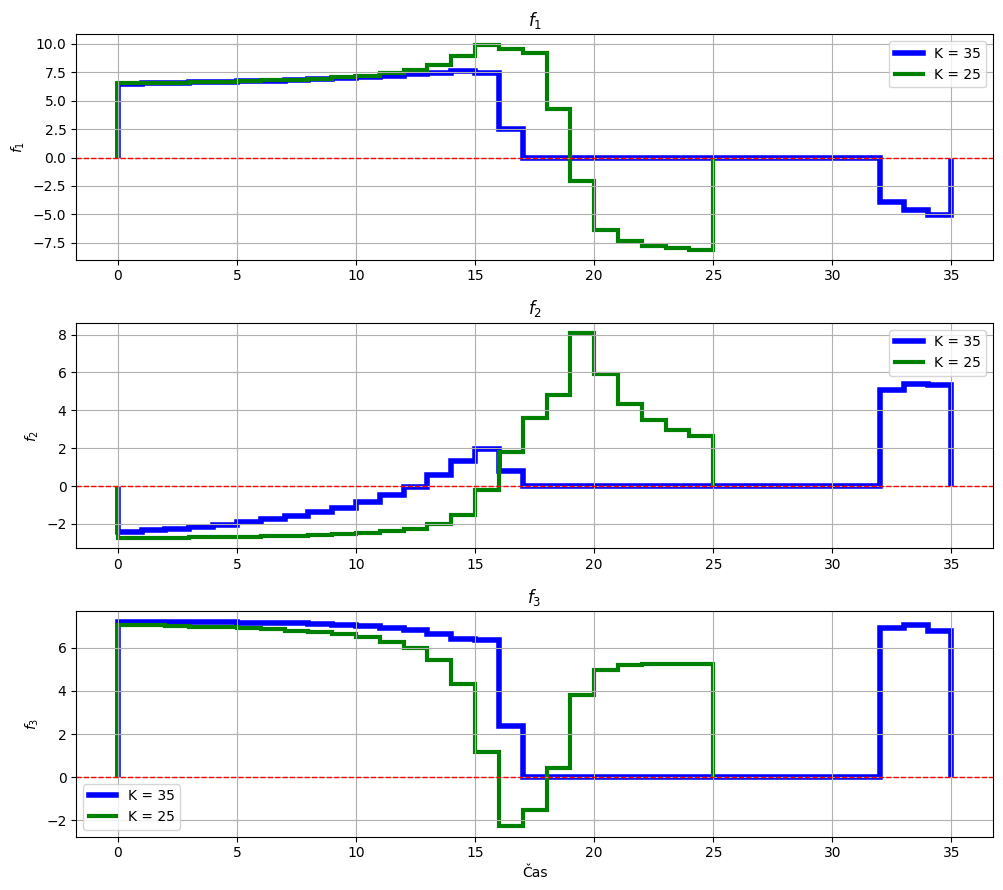

In [54]:
fig, axes = plt.subplots(3, 1, figsize=(10, 9), sharex=False)

nazvy = ["$f_1$", "$f_2$", "$f_3$"]

for i in range(3):
    axes[i].stairs(tah_opt[i, :], cas_p,
                   label="K = 35", linewidth=4, color="blue")
    axes[i].stairs(tah_min_opt[i, :], cas_m,
                   label="K = 25", linewidth=3, color="green")

    axes[i].axhline(0, color="red", linestyle="--", linewidth=1)
    axes[i].set_ylabel(f"$f_{i+1}$")
    axes[i].set_title(nazvy[i])
    axes[i].legend()
    axes[i].grid(True)

axes[-1].set_xlabel("Čas")

plt.tight_layout()
plt.savefig("zlozky_tahu.png", dpi=200, bbox_inches="tight")
plt.show()

### Výška kozmickej lode a veľkosť jej rýchlosti

Nakoniec vykreslíme výšku kozmickej lode $(p_k)_3$ a veľkosť jej rýchlosti $\|v_k\|_2$ v závislosti od času. Výšku získame z tretej zložky polohy a veľkosť rýchlosti vypočítame pomocou `np.linalg.norm`. Vytvoríme dva grafy, v ktorých porovnáme obe $K_p=35$ a $K_m=25$.


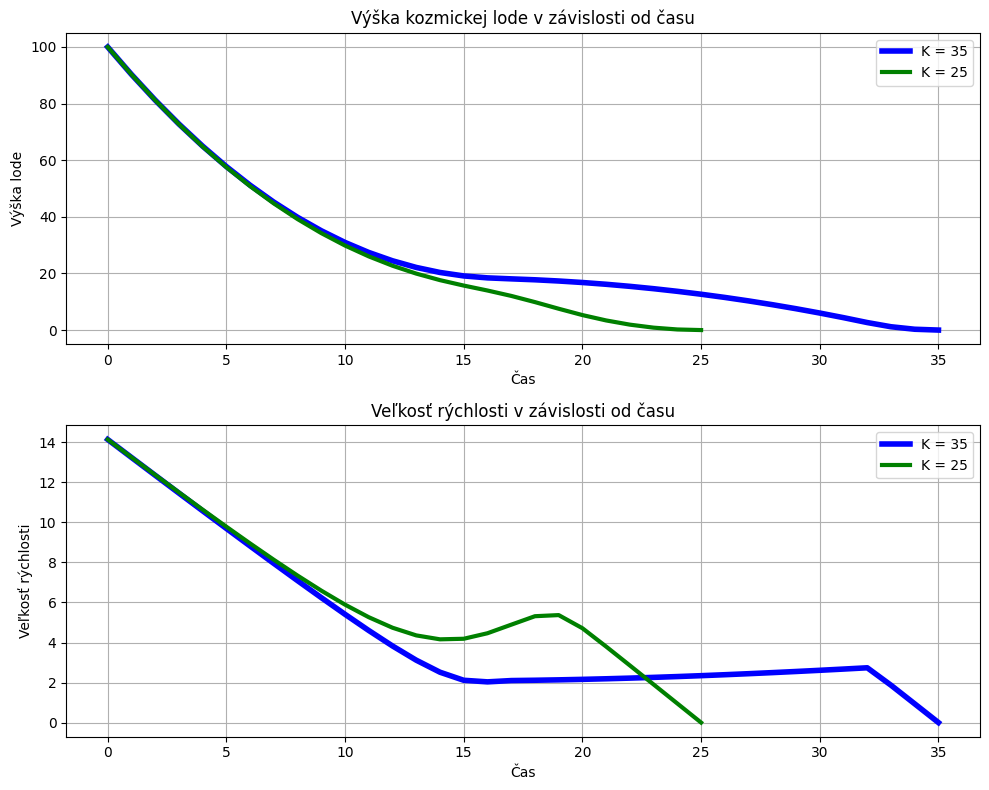

In [55]:
vyska_p = poloha_opt[2, :]
vyska_m = poloha_min_opt[2, :]

rychlost_p = np.linalg.norm(rychlost_opt, axis=0)
rychlost_m = np.linalg.norm(rychlost_min_opt, axis=0)

cas_p = np.arange(len(vyska_p)) * h
cas_m = np.arange(len(vyska_m)) * h

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].plot(cas_p, vyska_p,
             label="K = 35", linewidth=4, color="blue")
axes[0].plot(cas_m, vyska_m,
             label="K = 25", linewidth=3, color="green")

axes[0].set_xlabel("Čas")
axes[0].set_ylabel("Výška lode")
axes[0].set_title("Výška kozmickej lode v závislosti od času")
axes[0].legend()
axes[0].grid(True)

axes[1].plot(cas_p, rychlost_p,
             label="K = 35", linewidth=4, color="blue")
axes[1].plot(cas_m, rychlost_m,
             label="K = 25", linewidth=3, color="green")

axes[1].set_xlabel("Čas")
axes[1].set_ylabel("Veľkosť rýchlosti")
axes[1].set_title("Veľkosť rýchlosti v závislosti od času")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.savefig("vyska_rychlost.png", dpi=200, bbox_inches="tight")
plt.show()
